## mlpi26_Lect11_nbsup2.ipynb
# Supplement 2 — Where attention beats recurrence on a patrol robot
### Loop closure, multi-step forecasting, and what the attention weights actually show

*Companion to Raschka, Liu & Mirjalili, **Machine Learning with PyTorch and Scikit-Learn**, ch. 16
"Transformers – Improving Natural Language Processing with Attention Mechanisms", and the second half
of a robotics supplement pair. Supplement A ended with LSTMs and GRUs that carry the past in a
fixed vector of 48 numbers. This notebook builds two robot tasks where that vector is not enough,
and measures what a small transformer does better — and where it does not.*

**Learning objectives**

1. Explain attention as a *soft, content-addressed lookup table* and compute it by hand.
2. Build a loop-closure task ("has the rover crossed this floor feature before?") and show that an
   LSTM's accuracy collapses as the number of places to remember grows, while attention does not.
3. Validate an attention map with **occlusion** rather than trusting it as an explanation.
4. Forecast 8 s of a patrol route and show that attention discovers the lap period on its own.
5. Explain why positional information is mandatory for the forecaster.
6. Name a task where the LSTM is just as good and costs less.

**Runtime:** the full notebook trains 12 models: about 16 min on 2 CPU cores (much less on a laptop with
more cores). To shorten it, set `SWEEP_K = [4]` in section 4 — the rest of the notebook is unchanged.
Everything is synthetic and generated inline; no downloads.

In [1]:
import sys, time, json
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import roc_auc_score
import sklearn, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
torch.set_num_threads(2)
print("python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", np.__version__,
      "| sklearn", sklearn.__version__)

python 3.13.16 | torch 2.14.1+cu130 | numpy 2.5.3 | sklearn 1.9.1


## 1. The bottleneck

An RNN reads a run step by step and must decide, *at every step*, what to keep in its hidden state
**h** — before it knows what question will be asked at the end. Two things make that hard:

* **capacity** — h has a fixed size; remembering *K* things costs K times the room;
* **path length** — information from step t reaches step T only through T − t applications of the
  recurrent update.

Self-attention removes both. At the end of the run, the last token forms a **query** q and compares
it with a **key** kⱼ stored for every earlier token. The comparison scores become weights, and the
output is a weighted average of the tokens' **values** vⱼ:

$$\text{Attention}(Q,K,V)=\operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V .$$

Nothing has to be decided in advance: every token is kept, and the query picks what it needs. The
path from any token to the query is one step long. The price is that every query is compared with
every key — T² scores per head.

### Attention as a lookup, by hand

A robot has crossed four floor features and stored a 4-number IMU fingerprint for each (the keys).
It now feels a fingerprint (the query) that is a slightly noisy copy of place 3. The scaled dot
products, through a softmax, act as a *soft* "which stored place is this?".

In [2]:
rng = np.random.default_rng(3)
Kf = rng.normal(0, 0.6, (4, 4))               # 4 stored fingerprints (keys = values here)
q = Kf[2] + rng.normal(0, 0.1, 4)             # re-observation of place 3
scores = Kf @ q / np.sqrt(4)
w = np.exp(scores - scores.max()); w /= w.sum()
print("scores :", np.round(scores, 2))
print("weights:", np.round(w, 3), "-> place", w.argmax() + 1)

# the same thing with the PyTorch kernel used inside every transformer layer
Q = torch.tensor(q, dtype=torch.float32)[None, None, None]       # (batch, head, 1 query, d)
Kt = torch.tensor(Kf, dtype=torch.float32)[None, None]           # (batch, head, 4 keys, d)
out = F.scaled_dot_product_attention(Q, Kt, Kt)
print("by hand vs F.scaled_dot_product_attention, max |diff| =",
      float((out[0, 0, 0] - torch.tensor(w @ Kf, dtype=torch.float32)).abs().max()))

scores : [-1.73 -0.19  2.13 -0.4 ]
weights: [0.018 0.082 0.833 0.067] -> place 3
by hand vs F.scaled_dot_product_attention, max |diff| = 1.1920928955078125e-07


## 2. Task 1 — loop closure: has the rover been here before?

A warehouse rover rolls over floor features (expansion joints, drain grates, cable covers). Each one
produces a short IMU burst whose shape across four channels — its **fingerprint** d ∈ ℝ⁴ — is
specific to that feature. A bump detector flags *that* a feature was crossed (channel `bump`), but not
*which*.

Each run is 12.8 s at 10 Hz (128 samples). The rover crosses **K** features at random times, then one
more at the end of the run — the **query**. Half of all runs: the query is a re-observation (noise
σ = 0.15) of one of the K earlier features. Other half: a new feature. Label: *seen before?*

This is the core of **place recognition / loop closure** in SLAM, stripped to one decision. Detection
is trivial (the bump flag); the hard part is *memory and comparison*. Fresh runs are generated for
every training epoch, so neither model can overfit to a fixed set.

In [3]:
import numpy as np

LC_CH = ["acc_x", "acc_y", "acc_z", "gyro_z", "bump"]
MARK_LEN = 8
FP_NOISE = 0.15          # re-observation noise of a fingerprint
VIB_SD = 0.35            # background vibration on acc channels


def _bump(n):
    return np.sin(np.linspace(0, np.pi, n)) ** 2


def make_loop_run(rng, T, K=4, positive=None):
    """Returns X (T, 5), label, info. The query feature occupies the last MARK_LEN samples."""
    positive = rng.random() < 0.5 if positive is None else positive
    X = np.zeros((T, 5), np.float32)
    # background: vibration on acc, slowly varying turning on gyro
    X[:, :3] = rng.normal(0, VIB_SD, (T, 3))
    w = np.cumsum(rng.normal(0, 0.05, T))
    X[:, 3] = 0.6 * np.tanh(w) + rng.normal(0, 0.1, T)
    # K earlier features at non-overlapping random slots
    n_slots = (T - 2 * MARK_LEN) // MARK_LEN
    slots = np.sort(rng.choice(n_slots, K, replace=False))
    starts = slots * MARK_LEN
    D = rng.normal(0, 1, (K, 4))
    b = _bump(MARK_LEN)
    for s, d in zip(starts, D):
        X[s:s + MARK_LEN, :4] += b[:, None] * d[None, :] * 1.6
        X[s:s + MARK_LEN, 4] = 1.0
    if positive:
        j = int(rng.integers(K))
        dq = D[j] + rng.normal(0, FP_NOISE, 4)
        gap = T - MARK_LEN - starts[j]
    else:
        j, gap = -1, -1
        dq = rng.normal(0, 1, 4)
    X[T - MARK_LEN:, :4] += b[:, None] * dq[None, :] * 1.6
    X[T - MARK_LEN:, 4] = 1.0
    X[:, :4] += rng.normal(0, 0.05, (T, 4))
    return X, int(positive), dict(starts=starts, match=j, gap=int(gap))


def make_loop_dataset(n, seed, T, K=4):
    rng = np.random.default_rng(seed)
    out = [make_loop_run(rng, T, K, positive=(i % 2 == 0)) for i in range(n)]
    X = np.stack([o[0] for o in out])
    y = np.array([o[1] for o in out])
    info = [o[2] for o in out]
    return X, y, info


# ---------------- patrol forecasting ----------------
PT_DT = 0.2              # 5 Hz control log
CTX, HOR = 150, 40       # history steps, forecast horizon
LAP = 60                 # patrol timer: one lap every 60 steps (12 s)
LAP_RANGE = (LAP, LAP + 1)


def make_route(rng, P):
    """Piecewise yaw-rate / speed profile of one lap, length P."""
    w = np.zeros(P)
    v = np.zeros(P)
    t = 0
    while t < P:
        n = int(rng.integers(5, 16))
        if rng.random() < 0.5:
            wv, vv = 0.0, rng.uniform(0.9, 1.3)
        else:
            wv = rng.choice([-1, 1]) * rng.uniform(0.4, 1.0)
            vv = rng.uniform(0.4, 0.7)
        w[t:t + n] = wv
        v[t:t + n] = vv
        t += n
    # first-order smoothing (wrap-around so laps join smoothly)
    k = 0.45
    for arr in (w, v):
        for _ in range(2):
            y = arr.copy()
            for i in range(-P, P):
                y[i % P] = y[(i - 1) % P] + k * (arr[i % P] - y[(i - 1) % P])
            arr[:] = y
    return w, v


def make_patrol_run(rng, P=None):
    P = int(rng.integers(*LAP_RANGE)) if P is None else P
    w, v = make_route(rng, P)
    L = CTX + HOR
    phase = int(rng.integers(P))
    idx = (np.arange(L) + phase) % P
    lap_no = (np.arange(L) + phase) // P
    gain = 1 + rng.normal(0, 0.04, lap_no.max() + 1)        # lap-to-lap variation
    W = w[idx] * gain[lap_no]
    V = v[idx] * gain[lap_no]
    X = np.stack([W + rng.normal(0, 0.05, L), V + rng.normal(0, 0.03, L)], 1)
    return X.astype(np.float32), np.stack([W, V], 1).astype(np.float32), P


def make_patrol_dataset(n, seed):
    rng = np.random.default_rng(seed)
    out = [make_patrol_run(rng) for _ in range(n)]
    return (np.stack([o[0] for o in out]), np.stack([o[1] for o in out]),
            np.array([o[2] for o in out]))


def make_loop_batch(rng, n, T, K=4, return_starts=False):
    """Vectorised version of make_loop_run (balanced labels). Returns X, y, gap."""
    X = np.zeros((n, T, 5), np.float32)
    X[:, :, :3] = rng.normal(0, VIB_SD, (n, T, 3))
    w = np.cumsum(rng.normal(0, 0.05, (n, T)), 1)
    X[:, :, 3] = 0.3 * np.tanh(w) + rng.normal(0, 0.1, (n, T))
    n_slots = (T - 2 * MARK_LEN) // MARK_LEN
    slots = np.sort(np.argsort(rng.random((n, n_slots)), 1)[:, :K], 1)
    starts = slots * MARK_LEN
    D = rng.normal(0, 1, (n, K, 4))
    b = (_bump(MARK_LEN) * 1.6)[None, :, None]
    ar = np.arange(n)
    for k in range(K):
        for t in range(MARK_LEN):
            X[ar, starts[:, k] + t, :4] += b[0, t, 0] * D[:, k]
            X[ar, starts[:, k] + t, 4] = 1.0
    y = (np.arange(n) % 2 == 0).astype(np.int64)
    rng.shuffle(y)
    j = rng.integers(0, K, n)
    dq = np.where(y[:, None] == 1, D[ar, j] + rng.normal(0, FP_NOISE, (n, 4)), rng.normal(0, 1, (n, 4)))
    X[:, T - MARK_LEN:, :4] += b * dq[:, None, :]
    X[:, T - MARK_LEN:, 4] = 1.0
    X[:, :, :4] += rng.normal(0, 0.05, (n, T, 4))
    gap = np.where(y == 1, T - MARK_LEN - starts[ar, j], -1)
    if return_starts:
        return X, y, gap, starts, np.where(y == 1, j, -1)
    return X, y, gap


def patrol_inputs(X):
    """(N, CTX+HOR, 2) measurements -> (N, CTX+HOR, 3) model input with the future blanked."""
    N, L, _ = X.shape
    Z = np.zeros((N, L, 3), np.float32)
    Z[:, :CTX, :2] = X[:, :CTX]
    Z[:, CTX:, 2] = 1.0
    return Z

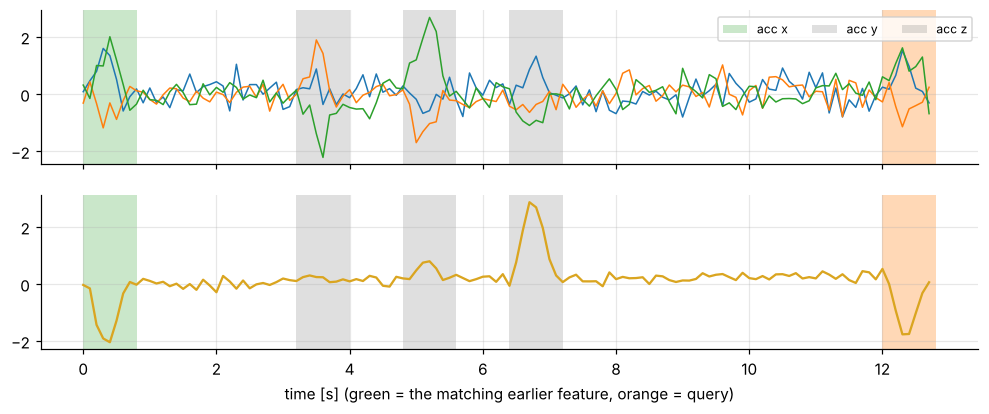

label: 1 | matching feature crossed 12.0 s before the query


In [4]:
Xd, yd, gd, std_, jd = make_loop_batch(np.random.default_rng(209), 1000, 128, 4, return_starts=True)
i = int(np.where((yd == 1) & (gd > 80))[0][0])
t = np.arange(128) * 0.1
fig, ax = plt.subplots(2, 1, figsize=(11, 4), sharex=True)
for a in ax:
    for k, s in enumerate(std_[i]):
        a.axvspan(s * .1, (s + 8) * .1, color="tab:green" if k == jd[i] else "grey", alpha=.25, lw=0)
    a.axvspan(12.0, 12.8, color="tab:orange", alpha=.3, lw=0)
ax[0].plot(t, Xd[i, :, :3], lw=1); ax[0].legend(["acc x", "acc y", "acc z"], ncol=3, fontsize=8)
ax[1].plot(t, Xd[i, :, 3], color="goldenrod"); ax[1].set_xlabel("time [s] (green = the matching earlier feature, orange = query)")
plt.show()
print("label:", yd[i], "| matching feature crossed", gd[i] * .1, "s before the query")

## 3. Two models with the *same* front end

To isolate the one thing being compared — **how information is mixed over time** — both models share a
convolutional stem: `Conv1d(5 → 48, kernel 8, stride 4)` turns the 128 samples into 31 tokens, each
summarising 0.8 s. Then:

* **LSTM** (96 units, forget gate opened, as in Supplement A) reads the 31 tokens and classifies from its
  last state;
* **transformer**: learned positional embedding + 2 Pre-LN blocks (4 heads, d = 48), classifying from the
  **last token** — the one that contains the query feature.

The `Block` class keeps its attention weights when `keep=True`, so we can inspect them later.

In [5]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(2)


class Block(nn.Module):
    '''Pre-LN transformer block that keeps its attention weights for inspection.'''
    def __init__(self, d, heads, ff, dropout=0.0):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d, ff), nn.GELU(), nn.Linear(ff, d))
        self.drop = nn.Dropout(dropout)
        self.weights, self.keep = None, False

    def forward(self, x, mask=None):
        y = self.ln1(x)
        a, w = self.attn(y, y, y, attn_mask=mask, need_weights=self.keep,
                         average_attn_weights=False)
        if self.keep:
            self.weights = w.detach()              # (B, heads, Tq, Tk)
        x = x + self.drop(a)
        return x + self.drop(self.ff(self.ln2(x)))


class Stem(nn.Module):
    '''Conv1d front end: 8-sample windows, stride 4 -> one token per 0.2 s.'''
    def __init__(self, c_in, d, k=8, stride=4, causal=False):
        super().__init__()
        self.k, self.causal = k, causal
        self.conv = nn.Conv1d(c_in, d, k, stride=stride)

    def forward(self, x):                        # x (B, T, C)
        x = x.transpose(1, 2)
        if self.causal:
            x = F.pad(x, (self.k - 1, 0))
        return F.gelu(self.conv(x)).transpose(1, 2)


class LoopTransformer(nn.Module):
    def __init__(self, c_in, n_tok, d=48, heads=4, layers=2, ff=96, use_pe=True):
        super().__init__()
        self.stem = Stem(c_in, d)
        self.pe = nn.Parameter(torch.zeros(1, n_tok, d)) if use_pe else None
        if use_pe:
            nn.init.normal_(self.pe, std=0.02)
        self.blocks = nn.ModuleList([Block(d, heads, ff) for _ in range(layers)])
        self.ln = nn.LayerNorm(d)
        self.head = nn.Linear(d, 1)

    def forward(self, x):
        h = self.stem(x)
        if self.pe is not None:
            h = h + self.pe[:, :h.shape[1]]
        for b in self.blocks:
            h = b(h)
        return self.head(self.ln(h[:, -1]))[:, 0]      # the query token reads out


class LoopLSTM(nn.Module):
    def __init__(self, c_in, d=48, hidden=96):
        super().__init__()
        self.stem = Stem(c_in, d)
        self.rnn = nn.LSTM(d, hidden, batch_first=True)
        with torch.no_grad():
            self.rnn.bias_ih_l0[hidden:2 * hidden].fill_(1.0)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        out, _ = self.rnn(self.stem(x))
        return self.head(out[:, -1])[:, 0]


def causal_mask(T, device=None):
    return torch.triu(torch.full((T, T), float("-inf"), device=device), diagonal=1)


class Forecaster(nn.Module):
    '''Decoder-only: causal conv embedding + causal self-attention, next-step prediction.'''
    def __init__(self, c_in=2, d=48, heads=4, layers=2, ff=96, max_len=256, use_pe=True):
        super().__init__()
        self.embed = Stem(c_in, d, k=4, stride=1, causal=True)
        self.pe = nn.Parameter(torch.randn(1, max_len, d) * 0.02) if use_pe else None
        self.blocks = nn.ModuleList([Block(d, heads, ff) for _ in range(layers)])
        self.ln = nn.LayerNorm(d)
        self.head = nn.Linear(d, c_in)

    def forward(self, x):
        T = x.shape[1]
        h = self.embed(x)
        if self.pe is not None:
            h = h + self.pe[:, :T]
        m = causal_mask(T, x.device)
        for b in self.blocks:
            h = b(h, m)
        return self.head(self.ln(h))


class LSTMForecaster(nn.Module):
    def __init__(self, c_in=2, hidden=96):
        super().__init__()
        self.rnn = nn.LSTM(c_in, hidden, num_layers=2, batch_first=True)
        with torch.no_grad():
            for l in range(2):
                getattr(self.rnn, f"bias_ih_l{l}")[hidden:2 * hidden].fill_(1.0)
        self.head = nn.Linear(hidden, c_in)

    def forward(self, x):
        return self.head(self.rnn(x)[0])


@torch.no_grad()
def rollout(model, ctx, H):
    '''Autoregressive forecast: feed each prediction back as the next input.'''
    seq = ctx.clone()
    preds = []
    for _ in range(H):
        nxt = model(seq)[:, -1:]
        preds.append(nxt)
        seq = torch.cat([seq, nxt], 1)
    return torch.cat(preds, 1)


class DirectForecaster(nn.Module):
    '''Context steps + H "future query" steps in one sequence; read the forecast off the
    query positions. Input channels: measurements (zeros in the future) + is_future flag.'''
    def __init__(self, c_in=3, c_out=2, d=48, heads=4, layers=2, ff=96, max_len=256, use_pe=True):
        super().__init__()
        self.embed = nn.Linear(c_in, d)
        self.pe = nn.Parameter(torch.randn(1, max_len, d) * 0.02) if use_pe else None
        self.blocks = nn.ModuleList([Block(d, heads, ff) for _ in range(layers)])
        self.ln = nn.LayerNorm(d)
        self.head = nn.Linear(d, c_out)

    def forward(self, x, H):
        h = self.embed(x)
        if self.pe is not None:
            h = h + self.pe[:, :x.shape[1]]
        for b in self.blocks:
            h = b(h)
        return self.head(self.ln(h[:, -H:]))


class LSTMDirect(nn.Module):
    '''Same input format: the LSTM reads the context, then keeps stepping through the
    H future slots (input = zeros + flag) and emits a forecast at each one.'''
    def __init__(self, c_in=3, c_out=2, hidden=96, layers=2):
        super().__init__()
        self.rnn = nn.LSTM(c_in, hidden, num_layers=layers, batch_first=True)
        with torch.no_grad():
            for l in range(layers):
                getattr(self.rnn, f"bias_ih_l{l}")[hidden:2 * hidden].fill_(1.0)
        self.head = nn.Linear(hidden, c_out)

    def forward(self, x, H):
        return self.head(self.rnn(x)[0][:, -H:])

In [6]:
SWEEP_K = [1, 2, 4, 8]        # places to remember per run.  Set [4] for a quick run.
LOOP_T, LOOP_K, LOOP_NPE, LOOP_EP = 128, 4, 6000, 20

def train_loop(kind, T, K, seed=1):
    torch.manual_seed(seed)
    m = LoopTransformer(5, (T - 8) // 4 + 1) if kind == "tf" else LoopLSTM(5)
    opt = torch.optim.Adam(m.parameters(), lr=2e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, LOOP_EP)
    g = torch.Generator().manual_seed(1234)
    rng = np.random.default_rng(100)                     # fresh runs every epoch
    t0 = time.time()
    for ep in range(LOOP_EP):
        m.train()
        Xn, yn, _ = make_loop_batch(rng, LOOP_NPE, T, K)
        Xn, yn = torch.from_numpy(Xn), torch.from_numpy(yn).float()
        for b in torch.randperm(len(Xn), generator=g).split(64):
            opt.zero_grad()
            loss = F.binary_cross_entropy_with_logits(m(Xn[b]), yn[b])
            loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        sched.step()
    return m, time.time() - t0

def loop_eval(m, X, y, gap, T):
    m.eval()
    with torch.no_grad():
        s = m(torch.from_numpy(X)).numpy()
    neg, edges = s[y == 0], np.linspace(0, T, 5).astype(int)
    by_gap = [roc_auc_score(np.r_[np.ones(((y == 1) & (gap >= lo) & (gap < hi)).sum()), np.zeros(len(neg))],
                            np.r_[s[(y == 1) & (gap >= lo) & (gap < hi)], neg]) for lo, hi in zip(edges[:-1], edges[1:])]
    return float(((s > 0) == y).mean()), float(roc_auc_score(y, s)), by_gap

print("params: LSTM", sum(p.numel() for p in LoopLSTM(5).parameters()),
      "| transformer", sum(p.numel() for p in LoopTransformer(5, 31).parameters()))

params: LSTM 61169 | transformer 41521


### A ceiling to compare against

If you were *given* the clean fingerprints, the best possible rule is "positive if the query is within
some distance of its nearest stored fingerprint". Its accuracy is the ceiling for any model:

In [7]:
rng = np.random.default_rng(0); n = 200000; oracle = {}
for K in [1, 2, 4, 8]:
    D = rng.normal(0, 1, (n, K, 4)); yy = rng.random(n) < .5; j = rng.integers(0, K, n)
    dq = np.where(yy[:, None], D[np.arange(n), j] + rng.normal(0, FP_NOISE, (n, 4)), rng.normal(0, 1, (n, 4)))
    dmin = np.linalg.norm(D - dq[:, None], axis=2).min(1)
    oracle[K] = max(((dmin < t) == yy).mean() for t in np.linspace(0.05, 2, 80))
print({k: round(v, 3) for k, v in oracle.items()})

{1: np.float64(0.997), 2: np.float64(0.995), 4: np.float64(0.991), 8: np.float64(0.985)}


## 4. Experiment: more places to remember

For each K we train both models on fresh data (20 epochs × 6000 runs) and test on the same 1000
held-out runs. AUC is also reported per *gap* — how long before the query the matching feature was
crossed.

In [8]:
res, loop_models = {}, {}
for K in SWEEP_K:
    Xte, yte, gte = make_loop_batch(np.random.default_rng(209), 1000, LOOP_T, K)
    for kind in ("lstm", "tf"):
        m, secs = train_loop(kind, LOOP_T, K)
        acc, auc, by_gap = loop_eval(m, Xte, yte, gte, LOOP_T)
        res[(K, kind)] = acc
        if K == LOOP_K: loop_models[kind] = m
        print(f"K={K}  {kind:5s} accuracy {acc:.3f}  AUC {auc:.3f}  AUC by gap {np.round(by_gap, 3)}  ({secs:.0f} s)")

K=1  lstm  accuracy 0.901  AUC 0.936  AUC by gap [0.937 0.938 0.933 0.935]  (39 s)


K=1  tf    accuracy 0.993  AUC 0.998  AUC by gap [0.998 0.999 0.998 0.997]  (88 s)


K=2  lstm  accuracy 0.716  AUC 0.793  AUC by gap [0.819 0.777 0.781 0.809]  (39 s)


K=2  tf    accuracy 0.969  AUC 0.989  AUC by gap [0.988 0.988 0.989 0.99 ]  (80 s)


K=4  lstm  accuracy 0.592  AUC 0.645  AUC by gap [0.613 0.665 0.634 0.654]  (39 s)


K=4  tf    accuracy 0.946  AUC 0.982  AUC by gap [0.984 0.979 0.981 0.983]  (76 s)


K=8  lstm  accuracy 0.552  AUC 0.581  AUC by gap [0.574 0.596 0.58  0.569]  (36 s)


K=8  tf    accuracy 0.923  AUC 0.965  AUC by gap [0.976 0.963 0.965 0.962]  (79 s)


With **one** place to remember the LSTM is respectable (0.901) and the transformer
is near the ceiling (0.993). As K grows the LSTM collapses towards chance —
0.716 at K = 2, 0.592 at K = 4, 0.552 at K = 8 —
while the transformer stays at 0.969, 0.946, 0.923,
tracking the ceiling.

Look at the AUC-by-gap columns at K = 4: the LSTM is poor at **every** gap, not only the long ones.
Over 31 tokens, *distance* is not what defeats it here — **capacity** is. It must squeeze four continuous
4-D fingerprints into its state without knowing which one will be asked about. Attention never squeezes:
the keys are all still there when the query arrives.

## 5. What does the query attend to — and is it telling the truth?

Attention weights are tempting to read as an explanation. Before believing them, test them: if the
model really uses the matching feature, **removing that feature** (overwriting it with background
vibration) should destroy the positive prediction, and removing a *different* feature should not.

In [9]:
Xte, yte, gte, ST, JM = make_loop_batch(np.random.default_rng(209), 1000, LOOP_T, LOOP_K, return_starts=True)
tf = loop_models["tf"]; tf.eval()
for b in tf.blocks: b.keep = True
with torch.no_grad():
    p_base = torch.sigmoid(tf(torch.from_numpy(Xte))).numpy()
A = [b.weights.mean(1)[:, -1].numpy() for b in tf.blocks]         # query row, head-averaged, per layer
for b in tf.blocks: b.keep = False
n_tok = A[0].shape[1]

share = {"match": [], "other markers": [], "background": [], "query itself": []}
hit = []
for i in np.where(yte == 1)[0]:
    a, s = A[-1][i], ST[i]
    toks = [set(range(max(0, st // 4 - 1), min(n_tok, st // 4 + 2))) for st in s]
    q, allm = set(range(n_tok - 2, n_tok)), set().union(*toks)
    share["match"].append(a[list(toks[JM[i]])].sum())
    share["other markers"].append(a[list(allm - toks[JM[i]])].sum())
    share["background"].append(a[list(set(range(n_tok)) - allm - q)].sum())
    share["query itself"].append(a[list(q)].sum())
    hit.append(abs(int(a[:n_tok - 2].argmax()) - s[JM[i]] // 4) <= 1)
print("last-layer attention of the query, positives:", {k: round(float(np.mean(v)), 3) for k, v in share.items()})
print("argmax of attention lands on the matching feature in", f"{np.mean(hit):.1%}", "of positives")

last-layer attention of the query, positives: {'match': 0.276, 'other markers': 0.294, 'background': 0.219, 'query itself': 0.212}
argmax of attention lands on the matching feature in 88.0% of positives


In [10]:
occ_rng = np.random.default_rng(5)
def occlude(X, st):
    X = X.copy()
    X[st:st + MARK_LEN, :3] = occ_rng.normal(0, VIB_SD, (MARK_LEN, 3))
    X[st:st + MARK_LEN, 3] = X[max(0, st - 1), 3]
    return X

pos_idx = np.where(yte == 1)[0][:300]
Xm = np.stack([occlude(Xte[i], ST[i][JM[i]]) for i in pos_idx])
Xo = np.stack([occlude(Xte[i], ST[i][(JM[i] + 1) % LOOP_K]) for i in pos_idx])
with torch.no_grad():
    p_m = torch.sigmoid(tf(torch.from_numpy(Xm))).numpy()
    p_o = torch.sigmoid(tf(torch.from_numpy(Xo))).numpy()
print(f"transformer P(seen before): intact {p_base[pos_idx].mean():.3f} | matching feature removed {p_m.mean():.3f}"
      f" | another feature removed {p_o.mean():.3f}")
print(f"positives flipped to 'new place' by removing the match: {((p_base[pos_idx] > .5) & (p_m < .5)).mean():.1%}")

transformer P(seen before): intact 0.914 | matching feature removed 0.115 | another feature removed 0.904
positives flipped to 'new place' by removing the match: 84.3%


Here the attention map and the occlusion test **agree**: 28% of the query's
last-layer attention lands on the matching feature alone — about three times what each of the other three features gets
(29% between them) — its argmax lands there in
88% of positives, and removing that feature drops the predicted probability
from 0.91 to about 0.12 (the random background used for occlusion makes the second decimal vary slightly between runs), while removing a different feature leaves it
at 0.91. That agreement is what licenses reading the map as an explanation.
It is not guaranteed in general (Jain & Wallace, 2019) — always run the test.

## 6. Task 2 — forecasting a patrol route

The rover repeats a closed patrol route on a fixed timer: **one lap every 60 control steps (12 s at
5 Hz)**. The route — which segments are straight, which turn and how hard — is random for every run,
so it cannot be memorised in the weights; it has to be read from the run's own history. Each lap also
varies by ±4 % in speed, and the measurements carry noise.

Given 150 steps (2.5 laps) of measured yaw rate and speed, predict the next **40 steps (8 s)**.

Both models get the *same* input: the 150 measured steps followed by 40 blank "future" slots with a
flag channel set to 1, and both read their forecast off the 40 future slots. The transformer can attend
from a future slot straight back to the same point of the previous lap. The LSTM has to have carried a
whole lap of the route in its state.

In [11]:
FC_N, FC_EP = 2000, 30
Xtr, Ctr, _ = make_patrol_dataset(FC_N, 7)
Xte_f, Cte_f, _ = make_patrol_dataset(500, 209)
Itr, Ite = torch.from_numpy(patrol_inputs(Xtr)), torch.from_numpy(patrol_inputs(Xte_f))
Ytr, Yte = torch.from_numpy(Ctr[:, CTX:]), torch.from_numpy(Cte_f[:, CTX:])
print("inputs", tuple(Itr.shape), "targets", tuple(Ytr.shape))

def train_fc(kind):
    torch.manual_seed(1)
    m = DirectForecaster() if kind == "tf" else LSTMDirect()
    opt = torch.optim.Adam(m.parameters(), lr=2e-3 if kind == "tf" else 3e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, FC_EP)
    g = torch.Generator().manual_seed(1234); t0 = time.time()
    for ep in range(FC_EP):
        m.train()
        for b in torch.randperm(len(Itr), generator=g).split(64):
            opt.zero_grad()
            loss = F.mse_loss(m(Itr[b], HOR), Ytr[b])
            loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        sched.step()
    return m, time.time() - t0

horizon_rmse = lambda pred: (pred - Yte).pow(2).mean(2).sqrt().mean(0).numpy()
fc_models, curves = {}, {}
for kind in ("lstm", "tf"):
    m, secs = train_fc(kind); m.eval()
    with torch.no_grad(): curves[kind] = horizon_rmse(m(Ite, HOR))
    fc_models[kind] = m
    print(f"{kind:5s} {sum(p.numel() for p in m.parameters())} params, {secs:.0f} s")
curves["persistence"] = horizon_rmse(torch.from_numpy(Xte_f[:, CTX - 1:CTX]).repeat(1, HOR, 1))
curves["copy one lap"] = horizon_rmse(torch.from_numpy(np.stack([x[CTX - LAP:CTX - LAP + HOR] for x in Xte_f])))
print(f"\n{'model':14s}" + "".join(f"  h={h:2d}" for h in (1, 5, 10, 20, 40)) + "   mean")
for k, e in curves.items():
    print(f"{k:14s}" + "".join(f" {e[h-1]:.3f}" for h in (1, 5, 10, 20, 40)) + f"  {e.mean():.3f}")

inputs (2000, 190, 3) targets (2000, 40, 2)


lstm  113474 params, 170 s


tf    50594 params, 234 s

model           h= 1  h= 5  h=10  h=20  h=40   mean
lstm           0.108 0.217 0.284 0.289 0.299  0.267
tf             0.071 0.038 0.039 0.043 0.043  0.040
persistence    0.067 0.235 0.373 0.434 0.441  0.388
copy one lap   0.049 0.049 0.050 0.050 0.049  0.050


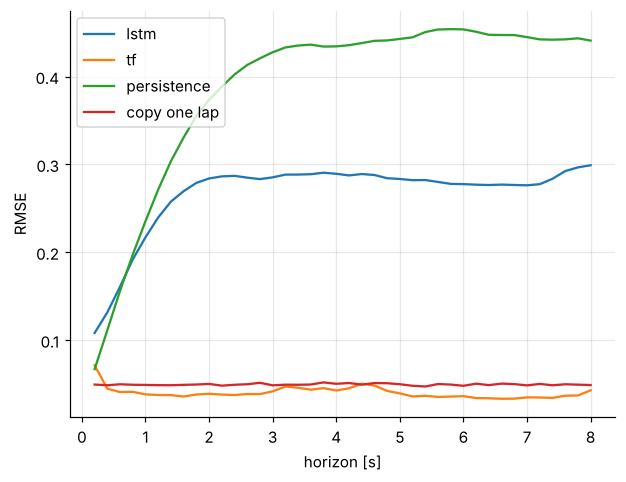

In [12]:
h = np.arange(1, HOR + 1) * PT_DT
for k, e in curves.items(): plt.plot(h, e, label=k)
plt.xlabel("horizon [s]"); plt.ylabel("RMSE"); plt.legend(); plt.show()

Persistence is fine for 0.2 s and useless after that. The LSTM (0.289 at h = 20) barely
improves on it beyond the first second: it has learned a smooth average, not the route. The transformer
(0.043 at h = 20, roughly flat over all 8 s) is even **better than copying the last lap**
(0.050) — it averages the two laps it can see, which cancels part of the
measurement noise.

### Where does a future slot look? — the lap period, found without being told

We average the attention weights over heads and 200 test runs and ask: how much attention does a future slot
put on a key that is *k* steps earlier?

layer 1: peak at lag 60 steps; mass within ±2 of 1 lap 0.244, of 2 laps 0.197; mass on future slots 0.044
layer 2: peak at lag 1 steps; mass within ±2 of 1 lap 0.025, of 2 laps 0.024; mass on future slots 0.403


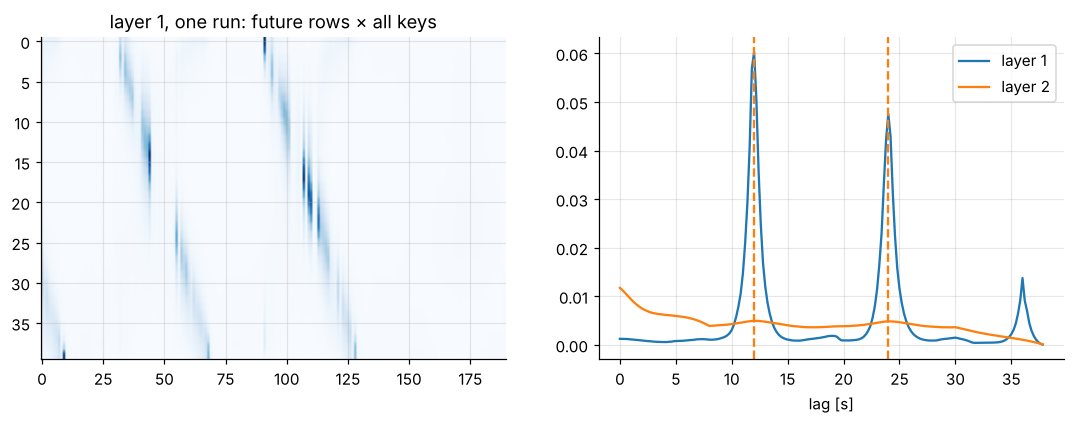

In [13]:
tfm = fc_models["tf"]
for b in tfm.blocks: b.keep = True
with torch.no_grad(): tfm(Ite[:200], HOR)
Wf = [b.weights.mean(1).numpy() for b in tfm.blocks]
for b in tfm.blocks: b.keep = False
Ltot = CTX + HOR
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for li, W in enumerate(Wf):
    lag = np.zeros(Ltot)
    for q in range(CTX, Ltot):
        lag[q - np.arange(q + 1)] += W[:, q, :q + 1].mean(0)
    lag /= HOR
    ax[1].plot(np.arange(Ltot) * PT_DT, lag, label=f"layer {li+1}")
    print(f"layer {li+1}: peak at lag {np.argmax(lag[1:]) + 1} steps;"
          f" mass within ±2 of 1 lap {lag[LAP-2:LAP+3].sum():.3f}, of 2 laps {lag[2*LAP-2:2*LAP+3].sum():.3f};"
          f" mass on future slots {W[:, CTX:, CTX:].sum(2).mean():.3f}")
ax[0].imshow(Wf[0][0, CTX:, :], aspect="auto", cmap="Blues"); ax[0].set_title("layer 1, one run: future rows × all keys")
for k in (1, 2): ax[1].axvline(k * LAP * PT_DT, ls="--", color="tab:orange")
ax[1].set_xlabel("lag [s]"); ax[1].legend(); plt.show()

Nobody told the model the period. Its **first** layer concentrates attention at lags of one and two laps
(peak at 60 steps; the lap is 60); the second layer mostly mixes the future
slots with each other (40% of its attention), smoothing the forecast. That is the "copy the same phase of an
earlier lap" rule, discovered from the loss.

### Why positions are not optional

In this design the 40 future slots all receive the *same* input (zeros plus the flag). Without a
positional embedding they are indistinguishable, so — whatever the weights — every slot must produce the
same forecast:

In [14]:
torch.manual_seed(1)
nope = DirectForecaster(use_pe=False).eval()
with torch.no_grad():
    o = nope(Ite[:8], HOR)
print("no positional embedding: max spread of the forecast across the 40 horizons =", float((o - o[:, :1]).abs().max()))

no positional embedding: max spread of the forecast across the 40 horizons = 0.0


A spread of zero (to float precision): a flat forecast is the *only* thing that model can express. Self-attention
is permutation-equivariant; order exists only if you put it in.

## 7. When a recurrent model is enough

Attention is not free: T² scores per head, more data to train, more hyperparameters. On a task where the
answer is a running statistic, there is nothing for attention to look up. Supplement A's terrain
classification is such a task. The cell below rebuilds that dataset and trains Supplement A's best recurrent
model there (the GRU) and a transformer (conv stem stride 2, [CLS] token, 2 blocks) on it.

In [15]:
import numpy as np

DT = 0.10                 # 10 Hz
TRACK = 0.50              # wheel separation [m]
CHANNELS = ["v_cmd", "w_cmd", "v_left", "v_right", "gyro_z", "acc_x", "acc_z"]
TERRAINS = ["concrete", "grass", "gravel"]
# vibration model of acc_z: AR(1) coefficient, innovation std (per m/s), impulse rate
VIB = {"concrete": (0.00, 0.30, 0.00),
       "grass":    (0.55, 0.30, 0.00),
       "gravel":   (0.00, 0.30, 0.06)}
SLIP_RATE = {"concrete": 0.6, "grass": 1.6, "gravel": 2.4}     # episodes per 10 s
ROLL = {"concrete": 0.02, "grass": 0.10, "gravel": 0.06}         # speed loss fraction
GYRO_NOISE, GYRO_BIAS, ENC_NOISE, ACC_NOISE = 0.03, 0.04, 0.03, 0.08


def _piecewise(rng, T, seg_s, choices_fn):
    out = np.empty(T)
    t = 0
    while t < T:
        n = int(rng.uniform(*seg_s) / DT)
        out[t:t + n] = choices_fn()
        t += n
    return out


def _lag(x, tau):
    a = DT / (tau + DT)
    y = np.empty_like(x)
    y[0] = x[0]
    for t in range(1, len(x)):
        y[t] = y[t - 1] + a * (x[t] - y[t - 1])
    return y


def make_run(rng, terrain=None, T=None):
    terrain = terrain if terrain is not None else TERRAINS[rng.integers(3)]
    T = T if T is not None else 10 * int(rng.integers(8, 21))  # 8-20 s, multiples of 10
    v_cmd = _piecewise(rng, T, (1.5, 4.0), lambda: rng.uniform(0.3, 1.0))
    w_cmd = _piecewise(rng, T, (1.0, 3.0),
                       lambda: 0.0 if rng.random() < 0.35 else rng.uniform(-0.9, 0.9))
    v = _lag(v_cmd, 0.35) * (1 - ROLL[terrain])
    w = _lag(w_cmd, 0.25)
    psi = np.cumsum(w) * DT

    # slip episodes: wheels spin faster than the body moves
    slip = np.zeros(T)
    extra_l = np.zeros(T)
    extra_r = np.zeros(T)
    n_ep = rng.poisson(SLIP_RATE[terrain] * T * DT / 10.0)
    for _ in range(n_ep):
        s = int(rng.integers(0, T - 8))
        d = int(rng.uniform(0.8, 2.5) / DT)
        e = min(T, s + d)
        slip[s:e] = 1
        env = np.sin(np.linspace(0, np.pi, e - s)) ** 0.5
        side = rng.random()
        extra_l[s:e] += env * rng.uniform(0.10, 0.35) * (side < 0.7)
        extra_r[s:e] += env * rng.uniform(0.10, 0.35) * (side > 0.3)
    # slipping wheels also drag the body a little
    v_true = v * (1 - 0.15 * slip)

    v_l = v_true - w * TRACK / 2 + extra_l + rng.normal(0, ENC_NOISE, T)
    v_r = v_true + w * TRACK / 2 + extra_r + rng.normal(0, ENC_NOISE, T)
    gyro_bias = rng.normal(0, GYRO_BIAS)                       # per-run, unknown to the model
    gyro = w + gyro_bias + rng.normal(0, GYRO_NOISE, T)
    acc_x = np.gradient(v_true, DT) + rng.normal(0, ACC_NOISE, T)

    a, s, imp = VIB[terrain]
    e = rng.normal(0, s, T) * (0.4 + v_true)
    z = np.empty(T)
    z[0] = e[0]
    for t in range(1, T):
        z[t] = a * z[t - 1] + e[t]
    if imp > 0:
        hits = rng.random(T) < imp
        z += hits * rng.choice([-1, 1], T) * rng.uniform(0.8, 1.6, T) * (0.4 + v_true)
    acc_z = z + rng.normal(0, ACC_NOISE, T)

    X = np.stack([v_cmd, w_cmd, v_l, v_r, gyro, acc_x, acc_z], 1).astype(np.float32)
    return X, dict(terrain=TERRAINS.index(terrain), slip=slip.astype(np.float32),
                   psi=psi.astype(np.float32), T=T, v=v_true, w=w, gyro_bias=gyro_bias)


def make_dataset(n, seed, T=None):
    rng = np.random.default_rng(seed)
    Xs, ys = [], []
    for i in range(n):
        X, y = make_run(rng, terrain=TERRAINS[i % 3], T=T)
        Xs.append(X)
        ys.append(y)
    return Xs, ys

In [16]:
import time
import numpy as np
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

torch.set_num_threads(2)


class Buckets:
    '''Groups runs by length. X: list of (T, C) arrays; Y: list of per-run targets.'''
    def __init__(self, Xs, Ys, mu, sd):
        self.groups = {}
        for i, (x, y) in enumerate(zip(Xs, Ys)):
            self.groups.setdefault(len(x), []).append(i)
        self.data = {}
        for T, idx in self.groups.items():
            X = torch.from_numpy(np.stack([(Xs[i] - mu) / sd for i in idx]).astype(np.float32))
            Y = torch.as_tensor(np.stack([Ys[i] for i in idx]))
            self.data[T] = (X, Y, np.array(idx))
        self.n = len(Xs)

    def batches(self, bs, gen=None):
        out = []
        for T, (X, Y, idx) in self.data.items():
            perm = torch.randperm(len(X), generator=gen) if gen is not None else torch.arange(len(X))
            for b in perm.split(bs):
                out.append((X[b], Y[b], idx[b.numpy()]))
        if gen is not None:
            order = torch.randperm(len(out), generator=gen).tolist()
            out = [out[i] for i in order]
        return out


class SeqNet(nn.Module):
    '''RNN / LSTM / GRU + small head. per_step=True gives an output at every time step.'''
    def __init__(self, cell, n_in, n_hidden, n_out, per_step=False,
                 bidirectional=False, open_gates=True):
        super().__init__()
        rnn_cls = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell]
        self.cell, self.per_step = cell, per_step
        self.rnn = rnn_cls(n_in, n_hidden, batch_first=True, bidirectional=bidirectional)
        k = 2 if bidirectional else 1
        self.head = nn.Sequential(nn.Linear(k * n_hidden, 32), nn.ReLU(), nn.Linear(32, n_out))
        if open_gates and cell in ("lstm", "gru"):
            open_gates_(self.rnn, cell, n_hidden)

    def forward(self, x):
        out, _ = self.rnn(x)                 # (B, T, k*H)
        if self.per_step:
            return self.head(out)
        if self.rnn.bidirectional:           # forward half at the end, backward half at the start
            H = self.rnn.hidden_size
            last = torch.cat([out[:, -1, :H], out[:, 0, H:]], 1)
        else:
            last = out[:, -1]
        return self.head(last)


def open_gates_(rnn, cell, h, value=1.0):
    '''LSTM: forget-gate bias +value.  GRU: update-gate bias -value would REDUCE memory in
    PyTorch's convention (h = (1-z)*n + z*h), so for GRU we set z's bias to +value.'''
    for name, p in rnn.named_parameters():
        if name.startswith("bias_ih"):
            with torch.no_grad():
                p[h:2 * h].fill_(value)


def train(model, loss_fn, data, epochs, lr=3e-3, bs=64, seed=1234,
          eval_fn=None, clip=1.0, log=False, record_grad=False):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    hist = []
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        tot, nb = 0.0, 0
        for X, Y, _ in data.batches(bs, gen):
            opt.zero_grad()
            loss = loss_fn(model(X), Y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            tot += loss.item()
            nb += 1
        sched.step()
        rec = {"epoch": ep + 1, "train_loss": tot / nb}
        if eval_fn is not None:
            rec.update(eval_fn(model))
        hist.append(rec)
        if log:
            print(rec, flush=True)
    return hist, time.time() - t0


@torch.no_grad()
def predict(model, data):
    '''Run the model bucket by bucket; returns {run index: output tensor}.'''
    model.eval()
    res = {}
    for X, Y, idx in data.batches(256):
        out = model(X)
        for k, i in enumerate(idx):
            res[int(i)] = out[k]
    return res

In [17]:
class TerrainTransformer(nn.Module):
    def __init__(self, c_in=7, d=48, heads=4, layers=2, ff=96, max_len=128):
        super().__init__()
        self.stem = nn.Conv1d(c_in, d, 4, stride=2)
        self.pe = nn.Parameter(torch.randn(1, max_len, d) * 0.02)
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        self.blocks = nn.ModuleList([Block(d, heads, ff, dropout=0.1) for _ in range(layers)])
        self.ln = nn.LayerNorm(d)
        self.head = nn.Linear(d, 3)

    def forward(self, x):
        h = F.gelu(self.stem(x.transpose(1, 2))).transpose(1, 2)
        h = torch.cat([self.cls.expand(len(h), -1, -1), h], 1) + self.pe[:, :h.shape[1] + 1]
        for b in self.blocks:
            h = b(h)
        return self.head(self.ln(h[:, 0]))

Xa_tr, ya_tr = make_dataset(900, 7); Xa_te, ya_te = make_dataset(600, 209)
allx = np.concatenate(Xa_tr); mu, sd = allx.mean(0), allx.std(0)
tr_t = Buckets(Xa_tr, [y["terrain"] for y in ya_tr], mu, sd)
te_t = Buckets(Xa_te, [y["terrain"] for y in ya_te], mu, sd)
yt = np.array([y["terrain"] for y in ya_te])
for kind in ("gru", "tf"):
    torch.manual_seed(1)
    m = SeqNet("gru", 7, 48, 3) if kind == "gru" else TerrainTransformer()
    hist, secs = train(m, lambda o, y: F.cross_entropy(o, y), tr_t, epochs=25, lr=3e-3 if kind == "gru" else 1e-3)
    Pm = predict(m, te_t)
    print(f"{kind:5s} accuracy {np.mean([Pm[i].argmax().item() == yt[i] for i in range(len(yt))]):.3f}"
          f"  {sum(p.numel() for p in m.parameters())} params  {secs:.0f} s")

gru   accuracy 0.963  9875 params  45 s


tf    accuracy 0.970  45747 params  48 s


On terrain the transformer reaches 0.970 against the GRU's 0.963, a gain of
0.7 points for 4.6× the parameters (training time is similar on this CPU). Compare the margins: +0.35 on loop
closure, +0.01 here. (Supplement A's *LSTM* is weaker on terrain, 0.818 — choosing
the right recurrent cell matters as much as choosing attention.) Attention pays off where the answer requires *looking something up* in the
past; when the answer is a running summary, a gated RNN does it with less.

## 8. What to remember

1. **Name what must be remembered, then count it.** One heading angle fits in 48 numbers; K fingerprints
   or a whole lap do not.
2. **Attention is a content-addressed lookup**: query · key → weights → mix of values. Every token stays
   available and the path to the query is one step.
3. **Same front end, different mixer** is the fair comparison. Here only the time-mixing layer differed.
4. **Compare against a ceiling** (the oracle) and a naive baseline (persistence, copy one lap).
5. **Positions are part of the input.** Without them the future slots are identical and the forecast is flat.
6. **Attention maps are hypotheses; occlusion tests them.**
7. **Pay T² only where it wins.** On a running-statistic task the best RNN is about as good and far cheaper.

## 9. Exercises

1. **Distance, not capacity.** Fix K = 1 and sweep the run length T ∈ {64, 128, 256, 512}. Does the LSTM
   degrade with T? Does the transformer? Report time per epoch as T grows.
2. **A variable patrol timer.** Draw the lap period from 45–80 steps per run. The transformer can no longer
   use a fixed positional offset — does it still work? Look at the attention map: what replaced the fixed lag?
3. **Give the LSTM a fair chance.** Increase its hidden size to 256 and its epochs to 40 on loop closure,
   K = 4. How much of the gap closes? Plot accuracy against parameter count for both models.
4. **One layer or two?** Train the loop-closure transformer with 1 layer and with 1 head. Which matters?
   Re-run the occlusion test on each.
5. **Attention that lies.** Add a decoy channel that copies the matching fingerprint's *timing* (a flag
   that fires on the matching feature). Does attention still point at the feature? Does occlusion of the
   feature still flip the prediction?
6. **Recurrent + attention.** Add one attention layer on top of the LSTM's outputs (the Bahdanau-style
   model the chapter starts from). Where on the K-sweep does it land?
7. **Autoregressive forecasting.** Replace the direct forecaster with a causal (decoder-only) transformer
   trained on next-step prediction and rolled out for 40 steps. Compare error growth with horizon.
8. **Real attention cost.** Measure forward-pass time and memory of the forecaster for context lengths
   150, 600 and 2400. Fit the exponent. At what length would patching (Supplement A of ch. 16) be needed?

## 10. References

* S. Raschka, Y. Liu, V. Mirjalili, *Machine Learning with PyTorch and Scikit-Learn*, Packt, 2022, ch. 16.
* A. Vaswani et al., "Attention is all you need", *NeurIPS*, 2017.
* D. Bahdanau, K. Cho, Y. Bengio, "Neural machine translation by jointly learning to align and translate", *ICLR*, 2015.
* R. Xiong et al., "On layer normalization in the transformer architecture", *ICML*, 2020 (Pre-LN).
* Y. Nie et al., "A time series is worth 64 words: long-term forecasting with transformers" (PatchTST), *ICLR*, 2023.
* B. Lim et al., "Temporal fusion transformers for interpretable multi-horizon time series forecasting",
  *Int. J. Forecasting* 37(4), 2021.
* S. Jain, B. C. Wallace, "Attention is not explanation", *NAACL*, 2019; S. Wiegreffe, Y. Pinter,
  "Attention is not not explanation", *EMNLP*, 2019.
* S. Lowry et al., "Visual place recognition: a survey", *IEEE Trans. Robotics* 32(1), 2016.
* PyTorch documentation: `torch.nn.MultiheadAttention`, `torch.nn.functional.scaled_dot_product_attention`.

Generated by Claude and customized by

<div align="center">
<img src="https://raw.githubusercontent.com/dewdotninja/sharing-github/refs/heads/master/dewninja_logo50.jpg" alt="dewninja"/>
</div>
<div align="center">dew.ninja 2026</div>